### Validate graph dataset

In [6]:
from torch_geometric.datasets import AmazonBook
from torch_geometric.utils import to_scipy_sparse_matrix

# Downloads the dataset and processes it into graph format automatically
dataset = AmazonBook(root='./data/AmazonBook')
data = dataset[0] # Contains edge_index of User-Item interactions

# HeteroData-safe stats
num_users = data['user'].num_nodes
num_items = data['book'].num_nodes
num_clicks = data['user', 'rates', 'book'].edge_index.size(1)

print(f"Num Users: {num_users}, Num Items: {num_items}")
print(f"Number of Clicks (Edges): {num_clicks}")

Num Users: 52643, Num Items: 91599
Number of Clicks (Edges): 2380730


In [7]:
data

HeteroData(
  user={ num_nodes=52643 },
  book={ num_nodes=91599 },
  (user, rates, book)={
    edge_index=[2, 2380730],
    edge_label_index=[2, 603378],
  },
  (book, rated_by, user)={ edge_index=[2, 2380730] }
)

In [1]:
import pandas as pd
import torch
from torch_geometric.data import HeteroData

# Example tabular node data
users = pd.DataFrame({
    "user_id": ["U1", "U2", "U3"],
    "age": [25, 34, 29]
})

books = pd.DataFrame({
    "book_id": ["B1", "B2", "B3"],
    "year": [2020, 2021, 2019]
})

# Example tabular relationship data
interactions = pd.DataFrame({
    "user_id": ["U1", "U1", "U2", "U3", "U3"],
    "book_id": ["B1", "B3", "B2", "B1", "B2"],
    "rating": [5, 4, 3, 5, 4]
})

# Create integer indices required by PyTorch Geometric
user_to_index = {
    user_id: index
    for index, user_id in enumerate(users["user_id"])
}

book_to_index = {
    book_id: index
    for index, book_id in enumerate(books["book_id"])
}

# Convert string IDs in the interaction table to integer node indices
source_nodes = interactions["user_id"].map(user_to_index).to_numpy()
target_nodes = interactions["book_id"].map(book_to_index).to_numpy()

edge_index = torch.tensor(
    [source_nodes, target_nodes],
    dtype=torch.long
)

# Build a heterogeneous graph
example_data = HeteroData()

# User node features: age
example_data["user"].x = torch.tensor(
    users[["age"]].to_numpy(),
    dtype=torch.float
)

# Book node features: publication year
example_data["book"].x = torch.tensor(
    books[["year"]].to_numpy(),
    dtype=torch.float
)

# User-book relationships
example_data["user", "rates", "book"].edge_index = edge_index

# Store the rating as an edge feature
example_data["user", "rates", "book"].edge_attr = torch.tensor(
    interactions[["rating"]].to_numpy(),
    dtype=torch.float
)

print("User table:")
display(users)

print("Book table:")
display(books)

print("Interaction table:")
display(interactions)

print("Converted graph:")
print(example_data)
print("\nEdge index:")
print(example_data["user", "rates", "book"].edge_index)

User table:


/tmp/ipykernel_8317/1178123350.py:38: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  edge_index = torch.tensor(


,user_id,age
0,U1,25
1,U2,34
2,U3,29


Book table:


,book_id,year
0,B1,2020
1,B2,2021
2,B3,2019


Interaction table:


,user_id,book_id,rating
0,U1,B1,5
1,U1,B3,4
2,U2,B2,3
3,U3,B1,5
4,U3,B2,4


Converted graph:
HeteroData(
  user={ x=[3, 1] },
  book={ x=[3, 1] },
  (user, rates, book)={
    edge_index=[2, 5],
    edge_attr=[5, 1],
  }
)

Edge index:
tensor([[0, 0, 1, 2, 2],
        [0, 2, 1, 0, 1]])


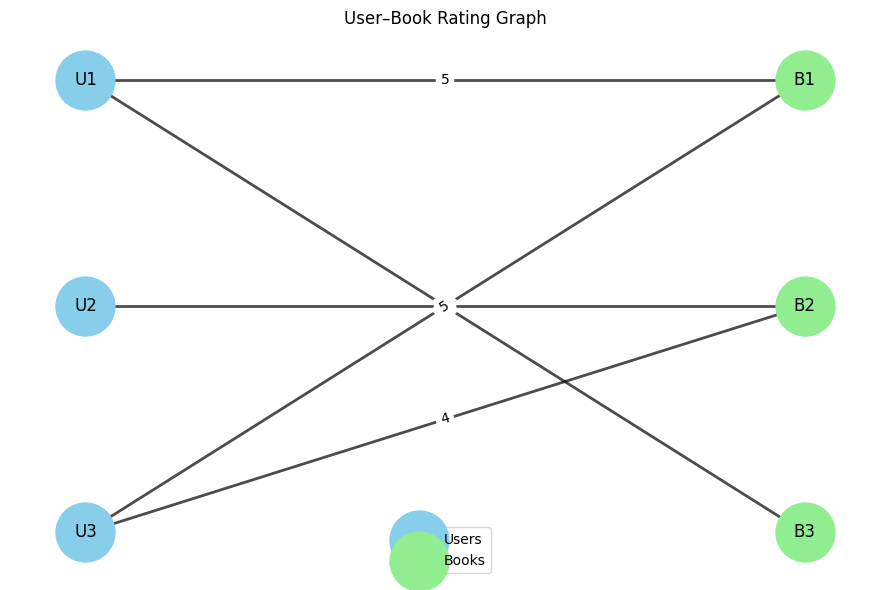

In [2]:
import networkx as nx

import matplotlib.pyplot as plt

graph = nx.Graph()

user_nodes = [f"user:{user_id}" for user_id in users["user_id"]]
book_nodes = [f"book:{book_id}" for book_id in books["book_id"]]

graph.add_nodes_from(user_nodes, node_type="user")
graph.add_nodes_from(book_nodes, node_type="book")

for row in interactions.itertuples(index=False):
    graph.add_edge(
        f"user:{row.user_id}",
        f"book:{row.book_id}",
        rating=row.rating,
    )

positions = {
    **{
        node: (0, index)
        for index, node in enumerate(reversed(user_nodes))
    },
    **{
        node: (1, index)
        for index, node in enumerate(reversed(book_nodes))
    },
}

plt.figure(figsize=(9, 6))

nx.draw_networkx_nodes(
    graph,
    positions,
    nodelist=user_nodes,
    node_color="skyblue",
    node_size=1800,
    label="Users",
)
nx.draw_networkx_nodes(
    graph,
    positions,
    nodelist=book_nodes,
    node_color="lightgreen",
    node_size=1800,
    label="Books",
)
nx.draw_networkx_edges(graph, positions, width=2, alpha=0.7)

node_labels = {
    node: node.split(":", maxsplit=1)[1]
    for node in graph.nodes
}
nx.draw_networkx_labels(graph, positions, labels=node_labels)

edge_labels = nx.get_edge_attributes(graph, "rating")
nx.draw_networkx_edge_labels(
    graph,
    positions,
    edge_labels=edge_labels,
    label_pos=0.5,
)

plt.title("User–Book Rating Graph")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()